# Busca em Largura (BFS)
## Implementação em C e análise experimental com Python

Neste notebook, os conceitos centrais da **Busca em Largura (Breadth-First Search — BFS)** serão implementados em **linguagem C**.

Python será usado somente como ferramenta auxiliar para:

- ler arquivos CSV gerados pelos programas C;
- organizar resultados experimentais;
- visualizar camadas, distâncias e custos;
- comparar lista e matriz de adjacências.

### Objetivos

Ao final das atividades, você deverá ser capaz de:

- implementar uma **fila FIFO** sem usar bibliotecas prontas;
- representar grafos com **listas de adjacência**;
- implementar BFS e explicar por que ela visita o grafo por **camadas**;
- manter corretamente `visitado[]`, `dist[]` e `pai[]`;
- reconstruir caminhos usando o vetor de predecessores;
- explicar por que BFS encontra caminhos mínimos em **número de arestas** em grafos sem pesos;
- percorrer grafos desconexos construindo uma floresta de busca;
- explicar por que o vértice deve ser marcado como visitado **no momento do enfileiramento**;
- implementar BFS também com **matriz de adjacências**;
- comparar experimentalmente as complexidades:
  - lista: \(\Theta(|V|+|E|)\);
  - matriz: \(\Theta(|V|^2)\).

> **Regra:** fila, grafo, BFS e reconstrução dos caminhos devem ser implementados em C. Python não deve substituir esses algoritmos.

# 0. Executando C no Google Colab

O Colab utiliza Python por padrão, mas pode criar e executar programas C.

### Criar um arquivo

```text
%%writefile programa.c
```

grava o restante da célula no arquivo `programa.c`.

### Compilar

```text
!gcc -Wall -Wextra -O2 -std=c11 programa.c -o programa
```

- `-Wall -Wextra`: habilitam avisos úteis;
- `-O2`: ativa otimizações;
- `-std=c11`: utiliza o padrão C11;
- `-o programa`: nome do executável.

### Executar

```text
!./programa
```

O `!` permite executar um comando do sistema operacional dentro do notebook.

# Parte I — A fila FIFO

A BFS utiliza uma **fila FIFO** (*First In, First Out*).

O primeiro vértice descoberto é também o primeiro a ser removido para exploração. Essa propriedade é fundamental para que todos os vértices da camada \(k\) sejam processados antes dos vértices da camada \(k+1\).

Implementaremos uma fila circular usando um vetor.

Uma fila manterá:

- `dados`: vetor;
- `capacidade`: número máximo de elementos;
- `inicio`: posição do primeiro elemento;
- `fim`: posição em que ocorrerá a próxima inserção;
- `quantidade`: número de elementos atualmente armazenados.

In [1]:
%%writefile fila.h
#ifndef FILA_H
#define FILA_H

typedef struct {
    int *dados;
    int capacidade;
    int inicio;
    int fim;
    int quantidade;
} Fila;

Fila *fila_cria(int capacidade);
int fila_vazia(const Fila *f);
int fila_cheia(const Fila *f);
int fila_enfileira(Fila *f, int valor);
int fila_desenfileira(Fila *f, int *valor);
void fila_imprime(const Fila *f);
void fila_libera(Fila *f);

#endif

Overwriting fila.h


# Exercício 1 — Implemente a fila

Complete `fila.c`.

### Requisitos

- não use estruturas prontas;
- use alocação dinâmica;
- trate fila vazia e fila cheia;
- a fila deve ser **circular**.

A atualização circular pode ser feita com:

```c
(indice + 1) % capacidade
```

### Antes de programar

Para uma fila de capacidade 5, simule no papel:

1. enfileira A, B, C;
2. remove A e B;
3. enfileira D, E, F.

Observe que o vetor pode reutilizar posições do início.

### Resposta — simulação da fila circular (capacidade 5)

| Passo | `dados` | `inicio` | `fim` | `quantidade` |
|---|---|---|---|---|
| enfileira A, B, C | `A B C _ _` | 0 | 3 | 3 |
| remove A e B | `_ _ C _ _` | 2 | 3 | 1 |
| enfileira D | `_ _ C D _` | 2 | 4 | 2 |
| enfileira E | `_ _ C D E` | 2 | 0 | 3 |
| enfileira F | `F _ C D E` | 2 | 1 | 4 |

Ao enfileirar E, `fim = (4 + 1) % 5 = 0`. Por isso F reutiliza a posição 0, que antes era de A. A ordem de remoção continua sendo C, D, E, F.

In [2]:
%%writefile fila.c
#include "fila.h"
#include <stdio.h>
#include <stdlib.h>

Fila *fila_cria(int capacidade)
{
    if (capacidade <= 0)
    {
        printf("[ERRO]: Capacidade inserida eh menor ou igual a 0\n");
        return NULL;
    }
    Fila *f = malloc(sizeof(Fila));
    if (f == NULL)
        return NULL;

    f->dados = malloc(capacidade * sizeof(int));
    if (f->dados == NULL)
    {
        free(f);
        return NULL;
    }

    f->capacidade = capacidade;
    f->inicio = 0;
    f->fim = 0;
    f->fim = 0;
    f->quantidade = 0;
    return f;
}

int fila_vazia(const Fila *f)
{
    if (f->quantidade == 0)
        return 1;
    else
        return 0;
}

int fila_cheia(const Fila *f)
{
    if (f->quantidade == f->capacidade)
        return 1;
    else
        return 0;
}

int fila_enfileira(Fila *f, int valor)
{
    if (fila_cheia(f))
        return 0;

    f->dados[f->fim] = valor;
    f->fim = (f->fim + 1) % f->capacidade;
    f->quantidade++;
    return 1;
}

int fila_desenfileira(Fila *f, int *valor)
{
    if (fila_vazia(f))
        return 0;

    *valor = f->dados[f->inicio];
    f->inicio = (f->inicio + 1) % f->capacidade;
    f->quantidade--;
    return 1;
}

void fila_imprime(const Fila *f)
{
    for (int i = 0; i < f->quantidade; i++)
    {
        printf("%d ", f->dados[(f->inicio + i) % f->capacidade]);
    }
    printf("\n");
}

void fila_libera(Fila *f)
{
    if (f == NULL)
        return;
    free(f->dados);
    free(f);
}

Overwriting fila.c


In [3]:
%%writefile teste_fila.c
#include <stdio.h>
#include "fila.h"

int main(void) {
    Fila *f = fila_cria(5);
    int x;

    if (!f) return 1;

    fila_enfileira(f, 10);
    fila_enfileira(f, 20);
    fila_enfileira(f, 30);

    printf("Fila inicial: ");
    fila_imprime(f);

    fila_desenfileira(f, &x);
    printf("Removeu %d\n", x);

    fila_desenfileira(f, &x);
    printf("Removeu %d\n", x);

    fila_enfileira(f, 40);
    fila_enfileira(f, 50);
    fila_enfileira(f, 60);

    printf("Após reutilizar posições: ");
    fila_imprime(f);

    printf("Vazia? %s\n", fila_vazia(f) ? "sim" : "não");
    printf("Cheia? %s\n", fila_cheia(f) ? "sim" : "não");

    fila_libera(f);
    return 0;
}

Overwriting teste_fila.c


In [4]:
!gcc -Wall -Wextra -O2 -std=c11 fila.c teste_fila.c -o teste_fila
!./teste_fila

Fila inicial: 10 20 30 
Removeu 10
Removeu 20
Após reutilizar posições: 30 40 50 60 
Vazia? não
Cheia? não


# Parte II — Representação por lista de adjacências

Usaremos uma lista ligada para representar os vizinhos de cada vértice.

```c
typedef struct NoAdj {
    int vertice;
    struct NoAdj *prox;
} NoAdj;
```

O grafo mantém, para cada vértice, o início e o fim da lista de adjacências.

Manter também o `fim` permite inserir vizinhos na ordem em que as arestas são adicionadas. Isso é útil porque a ordem dos vizinhos pode modificar a **ordem de visita e a árvore de predecessores**, embora não modifique as distâncias mínimas.

Usaremos os vértices:

```text
A=0, B=1, C=2, D=3, E=4, F=5, G=6, H=7
```

In [5]:
%%writefile grafo_lista.h
#ifndef GRAFO_LISTA_H
#define GRAFO_LISTA_H

typedef struct NoAdj {
    int vertice;
    struct NoAdj *prox;
} NoAdj;

typedef struct {
    int n;
    NoAdj **inicio;
    NoAdj **fim;
} GrafoLista;

GrafoLista *grafo_lista_cria(int n);
int grafo_lista_adiciona_aresta(GrafoLista *g, int u, int v);
void grafo_lista_imprime(const GrafoLista *g);
void grafo_lista_libera(GrafoLista *g);

#endif

Overwriting grafo_lista.h


# Exercício 2 — Construa o grafo com listas ligadas

Implemente:

- criação;
- inserção de uma aresta **não dirigida**;
- impressão;
- liberação de memória.

Para uma aresta `u-v`, é necessário inserir:

```text
v na lista de u
u na lista de v
```

No exemplo usado nas atividades, as arestas serão adicionadas nesta ordem:

```text
A-B
A-C
B-D
B-E
C-E
C-F
D-G
E-G
E-H
F-H
```

Com inserção no final, obtemos as listas:

```text
A: B, C
B: A, D, E
C: A, E, F
D: B, G
E: B, C, G, H
F: C, H
G: D, E
H: E, F
```

In [6]:
%%writefile grafo_lista.c
#include "grafo_lista.h"
#include <stdio.h>
#include <stdlib.h>

static int adiciona_direcionada(GrafoLista *g, int u, int v)
{
    NoAdj *no = malloc(sizeof(NoAdj));
    if (no == NULL)
        return 0;

    no->vertice = v;
    no->prox = NULL;

    if (g->inicio[u] == NULL)
        g->inicio[u] = no;
    else
        g->fim[u]->prox = no;
    g->fim[u] = no;
    return 1;
}

GrafoLista *grafo_lista_cria(int n)
{
    if (n <= 0)
        return NULL;

    GrafoLista *g = malloc(sizeof(GrafoLista));
    if (g == NULL)
        return NULL;

    g->n = n;
    g->inicio = calloc(n, sizeof(NoAdj *));
    g->fim = calloc(n, sizeof(NoAdj *));
    if (g->inicio == NULL || g->fim == NULL)
    {
        free(g->inicio);
        free(g->fim);
        free(g);
        return NULL;
    }
    return g;
}

int grafo_lista_adiciona_aresta(GrafoLista *g, int u, int v)
{
    if (u < 0 || u >= g->n || v < 0 || v >= g->n)
        return 0;

    if (!adiciona_direcionada(g, u, v))
        return 0;
    return adiciona_direcionada(g, v, u);
}

void grafo_lista_imprime(const GrafoLista *g)
{
    for (int u = 0; u < g->n; u++)
    {
        printf("%d:", u);
        for (NoAdj *p = g->inicio[u]; p != NULL; p = p->prox)
            printf(" %d", p->vertice);
        printf("\n");
    }
}

void grafo_lista_libera(GrafoLista *g)
{
    if (g == NULL)
        return;

    for (int u = 0; u < g->n; u++)
    {
        NoAdj *p = g->inicio[u];
        while (p != NULL)
        {
            NoAdj *prox = p->prox;
            free(p);
            p = prox;
        }
    }
    free(g->inicio);
    free(g->fim);
    free(g);
}

Overwriting grafo_lista.c


In [7]:
%%writefile teste_grafo.c
#include <stdio.h>
#include "grafo_lista.h"

static char nome(int v) {
    return (char)('A' + v);
}

int main(void) {
    GrafoLista *g = grafo_lista_cria(8);
    if (!g) return 1;

    int arestas[][2] = {
        {0,1}, {0,2}, {1,3}, {1,4}, {2,4},
        {2,5}, {3,6}, {4,6}, {4,7}, {5,7}
    };

    int m = sizeof(arestas) / sizeof(arestas[0]);

    for (int i = 0; i < m; i++)
        grafo_lista_adiciona_aresta(g, arestas[i][0], arestas[i][1]);

    printf("Listas de adjacência:\n");

    for (int u = 0; u < g->n; u++) {
        printf("%c: ", nome(u));

        for (NoAdj *p = g->inicio[u]; p; p = p->prox)
            printf("%c ", nome(p->vertice));

        printf("\n");
    }

    grafo_lista_libera(g);
    return 0;
}

Overwriting teste_grafo.c


In [25]:
!gcc -Wall -Wextra -O2 -std=c11 grafo_lista.c teste_grafo.c -o teste_grafo
!./teste_grafo

Listas de adjacência:
A: B C 
B: A D E 
C: A E F 
D: B G 
E: B C G H 
F: C H 
G: D E 
H: E F 


# Parte III — Estado mantido pela BFS

Durante a BFS, manteremos:

### `visitado[v]`

Indica se `v` já foi **descoberto e colocado na fila**.

### `dist[v]`

Número mínimo de arestas conhecido da origem até `v`.

Inicialização:

```text
dist[origem] = 0
dist[demais] = -1
```

Usaremos `-1` para representar distância ainda desconhecida.

### `pai[v]`

Vértice que descobriu `v`.

```text
pai[origem] = -1
```

O vetor `pai[]` permitirá reconstruir o caminho.

### `ordem[]`

Guardará a ordem em que os vértices são retirados da fila.

> **Importante:** marque um vértice como visitado no momento em que ele é **enfileirado**, não quando for removido.

In [9]:
%%writefile bfs.h
#ifndef BFS_H
#define BFS_H

#include "grafo_lista.h"

void bfs_lista(
    const GrafoLista *g,
    int origem,
    int visitado[],
    int dist[],
    int pai[],
    int ordem[],
    int *tam_ordem
);

#endif

Overwriting bfs.h


# Exercício 3 — Implemente a BFS

Use a fila desenvolvida no Exercício 1.

Pseudocódigo:

```text
para cada v:
    visitado[v] = falso
    dist[v] = infinito
    pai[v] = nulo

visitado[s] = verdadeiro
dist[s] = 0
enfileirar(s)

enquanto fila não estiver vazia:
    u = desenfileirar()

    para cada v em adj[u]:
        se v não foi visitado:
            visitado[v] = verdadeiro
            dist[v] = dist[u] + 1
            pai[v] = u
            enfileirar(v)
```

### Questão antes da implementação

Por que `visitado[v] = verdadeiro` deve aparecer **antes** de `enfileirar(v)`?

### Resposta — por que marcar antes de enfileirar?

Se `v` só fosse marcado ao sair da fila, outro vizinho de `v` poderia encontrá-lo ainda "não visitado" enquanto ele espera na fila e enfileirá-lo de novo.

Marcar no enfileiramento garante que cada vértice entra na fila **no máximo uma vez**. Com isso:

- a fila nunca passa de |V| elementos, então `fila_cria(g->n)` basta;
- `dist[v]` e `pai[v]` ficam com os valores da **primeira** descoberta, que é a de menor distância.

In [10]:
%%writefile bfs.c
#include "bfs.h"
#include "fila.h"
#include <stdlib.h>

void bfs_lista(const GrafoLista *g, int origem, int visitado[], int dist[],
               int pai[], int ordem[], int *tam_ordem)
{
    *tam_ordem = 0;
    for (int v = 0; v < g->n; v++)
    {
        visitado[v] = 0;
        dist[v] = -1;
        pai[v] = -1;
    }

    if (origem < 0 || origem >= g->n)
        return;

    Fila *f = fila_cria(g->n);
    if (f == NULL)
        return;

    visitado[origem] = 1;
    dist[origem] = 0;
    fila_enfileira(f, origem);

    while (!fila_vazia(f))
    {
        int u;
        fila_desenfileira(f, &u);
        ordem[(*tam_ordem)++] = u;

        for (NoAdj *p = g->inicio[u]; p != NULL; p = p->prox)
        {
            int v = p->vertice;
            if (!visitado[v])
            {
                visitado[v] = 1;
                dist[v] = dist[u] + 1;
                pai[v] = u;
                fila_enfileira(f, v);
            }
        }
    }

    fila_libera(f);
}

Overwriting bfs.c


In [11]:
%%writefile teste_bfs.c
#include <stdio.h>
#include "grafo_lista.h"
#include "bfs.h"

static char nome(int v) {
    return (char)('A' + v);
}

int main(void) {
    GrafoLista *g = grafo_lista_cria(8);

    int arestas[][2] = {
        {0,1}, {0,2}, {1,3}, {1,4}, {2,4},
        {2,5}, {3,6}, {4,6}, {4,7}, {5,7}
    };

    int m = sizeof(arestas) / sizeof(arestas[0]);

    for (int i = 0; i < m; i++)
        grafo_lista_adiciona_aresta(g, arestas[i][0], arestas[i][1]);

    int visitado[8], dist[8], pai[8], ordem[8], tam = 0;

    bfs_lista(g, 0, visitado, dist, pai, ordem, &tam);

    printf("Ordem de remoção da fila:\n");
    for (int i = 0; i < tam; i++)
        printf("%c ", nome(ordem[i]));

    printf("\n\nVértice  dist  pai\n");

    for (int v = 0; v < 8; v++) {
        printf("   %c      %2d    ", nome(v), dist[v]);

        if (pai[v] == -1)
            printf("-\n");
        else
            printf("%c\n", nome(pai[v]));
    }

    grafo_lista_libera(g);
    return 0;
}

Overwriting teste_bfs.c


In [26]:
!gcc -Wall -Wextra -O2 -std=c11 \
    fila.c grafo_lista.c bfs.c teste_bfs.c \
    -o teste_bfs

!./teste_bfs

Ordem de remoção da fila:
A B C D E F G H 

Vértice  dist  pai
   A       0    -
   B       1    A
   C       1    A
   D       2    B
   E       2    B
   F       2    C
   G       3    D
   H       3    E


## Resultado esperado para o exemplo

Se as listas de adjacência estiverem na ordem especificada, a BFS iniciada em `A` deve produzir:

```text
ordem: A B C D E F G H
```

Distâncias:

```text
A:0
B:1
C:1
D:2
E:2
F:2
G:3
H:3
```

O importante não é decorar a ordem. Observe a propriedade:

> todos os vértices com distância \(k\) são descobertos antes dos vértices com distância \(k+1\).

# Exercício 4 — Exporte o resultado da BFS para CSV

A implementação continua sendo C. O programa abaixo chama sua BFS e grava:

```text
vertice,distancia,pai,ordem
```

em `resultado_bfs.csv`.

O Python será usado depois apenas para visualizar as camadas.

In [13]:
%%writefile exporta_bfs.c
#include <stdio.h>
#include "grafo_lista.h"
#include "bfs.h"

int main(void) {
    GrafoLista *g = grafo_lista_cria(8);

    int arestas[][2] = {
        {0,1}, {0,2}, {1,3}, {1,4}, {2,4},
        {2,5}, {3,6}, {4,6}, {4,7}, {5,7}
    };

    int m = sizeof(arestas) / sizeof(arestas[0]);

    for (int i = 0; i < m; i++)
        grafo_lista_adiciona_aresta(g, arestas[i][0], arestas[i][1]);

    int visitado[8], dist[8], pai[8], ordem[8], tam = 0;

    bfs_lista(g, 0, visitado, dist, pai, ordem, &tam);

    int pos_ordem[8];

    for (int i = 0; i < tam; i++)
        pos_ordem[ordem[i]] = i;

    FILE *arq = fopen("resultado_bfs.csv", "w");
    if (!arq) return 1;

    fprintf(arq, "vertice,distancia,pai,ordem\n");

    for (int v = 0; v < 8; v++) {
        char pai_nome = pai[v] == -1 ? '-' : (char)('A' + pai[v]);

        fprintf(
            arq, "%c,%d,%c,%d\n",
            'A' + v, dist[v], pai_nome, pos_ordem[v]
        );
    }

    fclose(arq);
    grafo_lista_libera(g);

    printf("Arquivo resultado_bfs.csv criado.\n");
    return 0;
}

Overwriting exporta_bfs.c


In [27]:
!gcc -Wall -Wextra -O2 -std=c11 \
    fila.c grafo_lista.c bfs.c exporta_bfs.c \
    -o exporta_bfs

!./exporta_bfs

Arquivo resultado_bfs.csv criado.


# Python — lendo o CSV com `pandas`

`pandas` é uma biblioteca para manipulação de dados tabulares.

```python
import pandas as pd
```

O apelido `pd` é uma convenção.

```python
df = pd.read_csv("resultado_bfs.csv")
```

cria um **DataFrame**, uma estrutura semelhante a uma tabela com linhas e colunas.

O método `sort_values()` permite ordenar a visualização por uma coluna. Aqui ordenaremos pela ordem de remoção da fila.

In [28]:
import pandas as pd

bfs_df = pd.read_csv("resultado_bfs.csv")

display(
    bfs_df.sort_values("ordem")
)

,vertice,distancia,pai,ordem
0,A,0,-,0
1,B,1,A,1
2,C,1,A,2
3,D,2,B,3
4,E,2,B,4
5,F,2,C,5
6,G,3,D,6
7,H,3,E,7


# Python — visualizando as camadas com `matplotlib`

Não usaremos Python para calcular a BFS. As distâncias já foram calculadas em C.

`matplotlib` apenas transformará esses resultados em uma figura.

Usaremos:

- `plt.scatter(x,y)`: desenha pontos;
- `plt.annotate(texto, ...)`: escreve o nome do vértice próximo ao ponto;
- `plt.xlabel()` e `plt.ylabel()`: nomes dos eixos;
- `plt.show()`: exibe a figura.

No eixo x colocaremos a distância. Assim, vértices na mesma coluna pertencem à mesma camada.

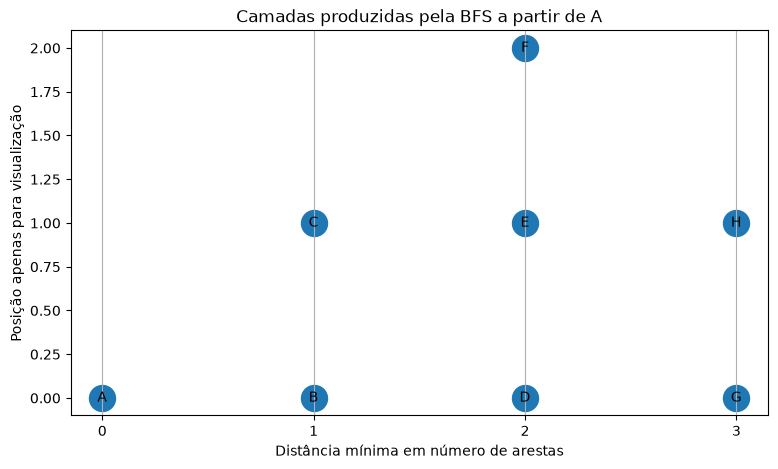

In [29]:
import matplotlib.pyplot as plt

camadas = bfs_df.sort_values(["distancia", "ordem"]).copy()

camadas["pos_na_camada"] = (
    camadas.groupby("distancia").cumcount()
)

plt.figure(figsize=(9, 5))

plt.scatter(
    camadas["distancia"],
    camadas["pos_na_camada"],
    s=350
)

for _, linha in camadas.iterrows():
    plt.annotate(
        linha["vertice"],
        (linha["distancia"], linha["pos_na_camada"]),
        ha="center",
        va="center"
    )

plt.xlabel("Distância mínima em número de arestas")
plt.ylabel("Posição apenas para visualização")
plt.title("Camadas produzidas pela BFS a partir de A")
plt.xticks(sorted(camadas["distancia"].unique()))
plt.grid(axis="x")
plt.show()

# Parte IV — Reconstrução de caminhos

O vetor `pai[]` descreve uma árvore de predecessores.

Para reconstruir um caminho até um vértice destino:

```text
destino
pai[destino]
pai[pai[destino]]
...
origem
```

Essa sequência aparece na ordem inversa. Podemos armazená-la em um vetor e depois imprimir de trás para frente.

No exemplo:

```text
pai[H] = E
pai[E] = B
pai[B] = A
```

Logo:

```text
A -> B -> E -> H
```

# Exercício 5 — Reconstrua o caminho

Implemente uma função que:

- receba `pai[]`, origem e destino;
- retorne o tamanho do caminho;
- escreva os vértices do caminho em um vetor;
- retorne 0 se o destino não for alcançável.

Não execute outra BFS dentro da função. Use apenas o vetor `pai[]`.

In [17]:
%%writefile caminho.c
#include <stdio.h>

int reconstroi_caminho(const int pai[], int origem, int destino, int caminho[],
                       int capacidade)
{
    if (destino < 0)
        return 0;

    int tam = 0;
    for (int v = destino; v != -1; v = pai[v])
    {
        if (tam == capacidade)
            return 0;
        caminho[tam++] = v;
    }

    if (caminho[tam - 1] != origem)
        return 0;

    for (int i = 0; i < tam / 2; i++)
    {
        int aux = caminho[i];
        caminho[i] = caminho[tam - 1 - i];
        caminho[tam - 1 - i] = aux;
    }
    return tam;
}

Overwriting caminho.c


In [18]:
%%writefile teste_caminho.c
#include <stdio.h>
#include "grafo_lista.h"
#include "bfs.h"

int reconstroi_caminho(
    const int pai[],
    int origem,
    int destino,
    int caminho[],
    int capacidade
);

int main(void) {
    GrafoLista *g = grafo_lista_cria(8);

    int arestas[][2] = {
        {0,1}, {0,2}, {1,3}, {1,4}, {2,4},
        {2,5}, {3,6}, {4,6}, {4,7}, {5,7}
    };

    int m = sizeof(arestas) / sizeof(arestas[0]);

    for (int i = 0; i < m; i++)
        grafo_lista_adiciona_aresta(g, arestas[i][0], arestas[i][1]);

    int vis[8], dist[8], pai[8], ordem[8], tam = 0;

    bfs_lista(g, 0, vis, dist, pai, ordem, &tam);

    int caminho[8];
    int n = reconstroi_caminho(pai, 0, 7, caminho, 8);

    printf("Caminho A -> H: ");

    for (int i = 0; i < n; i++) {
        if (i) printf(" -> ");
        printf("%c", 'A' + caminho[i]);
    }

    printf("\nNúmero de arestas: %d\n", n > 0 ? n - 1 : -1);

    grafo_lista_libera(g);
    return 0;
}

Overwriting teste_caminho.c


In [30]:
!gcc -Wall -Wextra -O2 -std=c11 \
    fila.c grafo_lista.c bfs.c caminho.c teste_caminho.c \
    -o teste_caminho

!./teste_caminho

Caminho A -> H: A -> B -> E -> H
Número de arestas: 3


# Parte V — Por que marcar no enfileiramento?

Considere o grafo:

```text
    B
   / \
  A   D
   \ /
    C
```

A origem é `A`.

Se `D` só for marcado quando sair da fila:

1. `B` descobre `D` e o enfileira;
2. antes de `D` sair da fila, `C` também encontra `D` ainda "não visitado";
3. `C` enfileira `D` novamente.

A BFS ainda pode terminar, mas realiza trabalho desnecessário e a fila pode conter duplicatas.

Execute o experimento abaixo e compare.

In [20]:
%%writefile marcacao_tardia.c
#include <stdio.h>
#include <stdlib.h>
#include "fila.h"
#include "grafo_lista.h"

static int bfs_correta(const GrafoLista *g, int s) {
    int *vis = calloc(g->n, sizeof(int));
    Fila *f = fila_cria(g->n * 4);
    int enfileiramentos = 0;

    vis[s] = 1;
    fila_enfileira(f, s);
    enfileiramentos++;

    while (!fila_vazia(f)) {
        int u;
        fila_desenfileira(f, &u);

        for (NoAdj *p = g->inicio[u]; p; p = p->prox) {
            int v = p->vertice;

            if (!vis[v]) {
                vis[v] = 1;  /* marca ANTES */
                fila_enfileira(f, v);
                enfileiramentos++;
            }
        }
    }

    free(vis);
    fila_libera(f);
    return enfileiramentos;
}

static int bfs_marcando_tarde(const GrafoLista *g, int s) {
    int *vis = calloc(g->n, sizeof(int));
    Fila *f = fila_cria(g->n * 10);
    int enfileiramentos = 0;

    fila_enfileira(f, s);
    enfileiramentos++;

    while (!fila_vazia(f)) {
        int u;
        fila_desenfileira(f, &u);

        if (vis[u])
            continue;

        vis[u] = 1;  /* ERRADO: marca somente ao remover */

        for (NoAdj *p = g->inicio[u]; p; p = p->prox) {
            int v = p->vertice;

            if (!vis[v]) {
                fila_enfileira(f, v);
                enfileiramentos++;
            }
        }
    }

    free(vis);
    fila_libera(f);
    return enfileiramentos;
}

int main(void) {
    GrafoLista *g = grafo_lista_cria(4);

    grafo_lista_adiciona_aresta(g, 0, 1); /* A-B */
    grafo_lista_adiciona_aresta(g, 0, 2); /* A-C */
    grafo_lista_adiciona_aresta(g, 1, 3); /* B-D */
    grafo_lista_adiciona_aresta(g, 2, 3); /* C-D */

    printf("Marcação no enfileiramento: %d inserções na fila\n",
           bfs_correta(g, 0));

    printf("Marcação tardia:           %d inserções na fila\n",
           bfs_marcando_tarde(g, 0));

    grafo_lista_libera(g);
    return 0;
}

Overwriting marcacao_tardia.c


In [21]:
!gcc -Wall -Wextra -O2 -std=c11 \
    fila.c grafo_lista.c marcacao_tardia.c \
    -o marcacao_tardia

!./marcacao_tardia

Marcação no enfileiramento: 4 inserções na fila
Marcação tardia:           5 inserções na fila


## Questões sobre a marcação

1. Por que `D` pode entrar mais de uma vez na fila?
2. O problema ficaria mais grave em grafos com muitos caminhos convergindo para os mesmos vértices?
3. Qual é a regra segura?

> **Regra:** se `v` será colocado na fila, marque `visitado[v]` **antes** de inseri-lo.

### Respostas

1. `D` é vizinho de `B` e de `C`, que estão na mesma camada. Ao processar `B`, `D` entra na fila **sem ser marcado**. Quando `C` é processado, `D` ainda não saiu da fila e, portanto, continua desmarcado; então é enfileirado de novo. Por isso foram 5 inserções em vez de 4.
2. Sim. Com a marcação tardia, um vértice pode entrar na fila uma vez por aresta que chega nele antes de ele ser removido. O número de inserções passa de |V| para até Θ(|E|), e a fila precisa de capacidade proporcional a |E| (por isso `bfs_marcando_tarde` usa `n * 10`). Em grafos densos, isso chega a Θ(|V|²) inserções.
3. A regra segura é marcar `visitado[v]` (e definir `dist[v]` e `pai[v]`) **no momento em que `v` é enfileirado**.

# Parte VI — Grafos desconexos

Uma BFS iniciada em `s` alcança apenas a **componente conexa** que contém `s`.

Para percorrer todo o grafo:

```text
para cada vértice v:
    se v ainda não foi visitado:
        execute uma BFS a partir de v
```

O resultado é uma **floresta de busca**.

Além de visitar todo o grafo, esse procedimento permite numerar as componentes conexas.

# Exercício 6 — Componentes conexas com BFS

Implemente:

```c
int componentes_bfs(const GrafoLista *g, int componente[]);
```

A função deve:

- percorrer todo o grafo;
- atribuir um identificador de componente a cada vértice;
- retornar o número total de componentes.

Use sua própria fila.

In [22]:
%%writefile componentes.c
#include "fila.h"
#include "grafo_lista.h"
#include <stdlib.h>

int componentes_bfs(const GrafoLista *g, int componente[])
{
    Fila *f = fila_cria(g->n);
    if (f == NULL)
        return -1;

    for (int v = 0; v < g->n; v++)
        componente[v] = -1;

    int qtd = 0;
    for (int s = 0; s < g->n; s++)
    {
        if (componente[s] != -1)
            continue;

        componente[s] = qtd;
        fila_enfileira(f, s);

        while (!fila_vazia(f))
        {
            int u;
            fila_desenfileira(f, &u);

            for (NoAdj *p = g->inicio[u]; p != NULL; p = p->prox)
            {
                int v = p->vertice;
                if (componente[v] == -1)
                {
                    componente[v] = qtd;
                    fila_enfileira(f, v);
                }
            }
        }
        qtd++;
    }

    fila_libera(f);
    return qtd;
}

Overwriting componentes.c


In [23]:
%%writefile teste_componentes.c
#include <stdio.h>
#include "grafo_lista.h"

int componentes_bfs(
    const GrafoLista *g,
    int componente[]
);

int main(void) {
    GrafoLista *g = grafo_lista_cria(7);

    /* componente 0: A-B-C-D */
    grafo_lista_adiciona_aresta(g, 0, 1);
    grafo_lista_adiciona_aresta(g, 1, 2);
    grafo_lista_adiciona_aresta(g, 2, 3);
    grafo_lista_adiciona_aresta(g, 3, 0);

    /* componente 1: E-F-G */
    grafo_lista_adiciona_aresta(g, 4, 5);
    grafo_lista_adiciona_aresta(g, 5, 6);

    int componente[7];

    int qtd = componentes_bfs(g, componente);

    printf("Número de componentes: %d\n", qtd);

    for (int v = 0; v < 7; v++)
        printf("%c -> componente %d\n", 'A' + v, componente[v]);

    grafo_lista_libera(g);
    return 0;
}

Overwriting teste_componentes.c


In [31]:
!gcc -Wall -Wextra -O2 -std=c11 \
    fila.c grafo_lista.c componentes.c teste_componentes.c \
    -o teste_componentes

!./teste_componentes

Número de componentes: 2
A -> componente 0
B -> componente 0
C -> componente 0
D -> componente 0
E -> componente 1
F -> componente 1
G -> componente 1


# Parte VII — Matriz de adjacências

Em uma matriz de adjacências:

```text
matriz[u][v] = 1  se existe aresta u-v
matriz[u][v] = 0  caso contrário
```

Para um grafo não dirigido, a matriz é simétrica.

Uma representação linear contígua pode ser acessada por:

```c
matriz[u * n + v]
```

### Consequência para a BFS

Ao remover `u` da fila, precisamos testar:

```text
v = 0, 1, ..., n-1
```

para descobrir seus vizinhos.

Mesmo que `u` tenha poucos vizinhos, examinamos toda a linha. Por isso, a BFS com matriz tem custo \(\Theta(|V|^2)\).

In [25]:
%%writefile grafo_matriz.h
#ifndef GRAFO_MATRIZ_H
#define GRAFO_MATRIZ_H

typedef struct {
    int n;
    unsigned char *matriz;
} GrafoMatriz;

GrafoMatriz *grafo_matriz_cria(int n);
void grafo_matriz_adiciona_aresta(GrafoMatriz *g, int u, int v);
int grafo_matriz_tem_aresta(const GrafoMatriz *g, int u, int v);
void grafo_matriz_libera(GrafoMatriz *g);

#endif

Overwriting grafo_matriz.h


# Exercício 7 — Matriz + BFS

Implemente:

1. criação da matriz;
2. inserção de aresta não dirigida;
3. consulta de aresta;
4. liberação;
5. BFS usando matriz.

Use os mesmos vetores:

```text
visitado[]
dist[]
pai[]
ordem[]
```

e verifique se as distâncias são iguais às obtidas com a lista.

In [26]:
%%writefile grafo_matriz.c
#include "grafo_matriz.h"
#include <stdlib.h>

GrafoMatriz *grafo_matriz_cria(int n)
{
    if (n <= 0)
        return NULL;

    GrafoMatriz *g = malloc(sizeof(GrafoMatriz));
    if (g == NULL)
        return NULL;

    g->n = n;
    g->matriz = calloc((size_t)n * n, sizeof(unsigned char));
    if (g->matriz == NULL)
    {
        free(g);
        return NULL;
    }
    return g;
}

void grafo_matriz_adiciona_aresta(GrafoMatriz *g, int u, int v)
{
    if (u < 0 || u >= g->n || v < 0 || v >= g->n)
        return;

    g->matriz[(size_t)u * g->n + v] = 1;
    g->matriz[(size_t)v * g->n + u] = 1;
}

int grafo_matriz_tem_aresta(const GrafoMatriz *g, int u, int v)
{
    if (u < 0 || u >= g->n || v < 0 || v >= g->n)
        return 0;

    return g->matriz[(size_t)u * g->n + v];
}

void grafo_matriz_libera(GrafoMatriz *g)
{
    if (g == NULL)
        return;

    free(g->matriz);
    free(g);
}

Overwriting grafo_matriz.c


In [27]:
%%writefile bfs_matriz.c
#include "fila.h"
#include "grafo_matriz.h"
#include <stdlib.h>

void bfs_matriz(const GrafoMatriz *g, int origem, int visitado[], int dist[],
                int pai[], int ordem[], int *tam_ordem)
{
    *tam_ordem = 0;
    for (int v = 0; v < g->n; v++)
    {
        visitado[v] = 0;
        dist[v] = -1;
        pai[v] = -1;
    }

    if (origem < 0 || origem >= g->n)
        return;

    Fila *f = fila_cria(g->n);
    if (f == NULL)
        return;

    visitado[origem] = 1;
    dist[origem] = 0;
    fila_enfileira(f, origem);

    while (!fila_vazia(f))
    {
        int u;
        fila_desenfileira(f, &u);
        ordem[(*tam_ordem)++] = u;

        for (int v = 0; v < g->n; v++)
        {
            if (grafo_matriz_tem_aresta(g, u, v) && !visitado[v])
            {
                visitado[v] = 1;
                dist[v] = dist[u] + 1;
                pai[v] = u;
                fila_enfileira(f, v);
            }
        }
    }

    fila_libera(f);
}

Overwriting bfs_matriz.c


In [28]:
%%writefile teste_bfs_matriz.c
#include <stdio.h>
#include "grafo_matriz.h"

void bfs_matriz(
    const GrafoMatriz *g,
    int origem,
    int visitado[],
    int dist[],
    int pai[],
    int ordem[],
    int *tam_ordem
);

int main(void) {
    GrafoMatriz *g = grafo_matriz_cria(8);

    int arestas[][2] = {
        {0,1}, {0,2}, {1,3}, {1,4}, {2,4},
        {2,5}, {3,6}, {4,6}, {4,7}, {5,7}
    };

    int m = sizeof(arestas) / sizeof(arestas[0]);

    for (int i = 0; i < m; i++)
        grafo_matriz_adiciona_aresta(g, arestas[i][0], arestas[i][1]);

    int vis[8], dist[8], pai[8], ordem[8], tam = 0;

    bfs_matriz(g, 0, vis, dist, pai, ordem, &tam);

    printf("Distâncias a partir de A:\n");

    for (int v = 0; v < 8; v++)
        printf("%c: %d\n", 'A' + v, dist[v]);

    grafo_matriz_libera(g);
    return 0;
}

Overwriting teste_bfs_matriz.c


In [32]:
!gcc -Wall -Wextra -O2 -std=c11 \
    fila.c grafo_matriz.c bfs_matriz.c teste_bfs_matriz.c \
    -o teste_bfs_matriz

!./teste_bfs_matriz

Distâncias a partir de A:
A: 0
B: 1
C: 1
D: 2
E: 2
F: 2
G: 3
H: 3


### Verificação — lista × matriz

As distâncias obtidas com a matriz (`A:0, B:1, C:1, D:2, E:2, F:2, G:3, H:3`) são iguais às obtidas com a lista.

Neste exemplo a ordem de visita e os pais também coincidem. A matriz percorre `v = 0..n-1` em ordem crescente, e as listas deste grafo também ficaram em ordem crescente. Com outra ordem de inserção das arestas, `pai[]` poderia mudar, mas `dist[]` não.

# Exercício 8 — Experimento: lista × matriz

Agora faremos uma comparação experimental.

O programa abaixo cria **o mesmo grafo esparso** nas duas representações.

Para cada tamanho:

- garante conectividade adicionando uma cadeia;
- adiciona arestas aleatórias até aproximadamente \(2|V|\) arestas;
- executa BFS;
- mede:
  - tempo;
  - número de verificações de vizinhança.

### Métrica estrutural

Na lista, uma verificação corresponde a examinar uma entrada de lista de adjacência.

Na matriz, uma verificação corresponde a testar `matriz[u][v]`.

Essa métrica ajuda a observar a diferença de complexidade mesmo quando o relógio possui ruído.

In [30]:
%%writefile benchmark_bfs.c
#include <stdio.h>
#include <stdlib.h>
#include <time.h>
#include "fila.h"
#include "grafo_lista.h"
#include "grafo_matriz.h"

static long long bfs_lista_conta(const GrafoLista *g, int s) {
    int *vis = calloc(g->n, sizeof(int));
    Fila *f = fila_cria(g->n);
    long long checks = 0;

    vis[s] = 1;
    fila_enfileira(f, s);

    while (!fila_vazia(f)) {
        int u;
        fila_desenfileira(f, &u);

        for (NoAdj *p = g->inicio[u]; p; p = p->prox) {
            checks++;
            int v = p->vertice;

            if (!vis[v]) {
                vis[v] = 1;
                fila_enfileira(f, v);
            }
        }
    }

    free(vis);
    fila_libera(f);
    return checks;
}

static long long bfs_matriz_conta(const GrafoMatriz *g, int s) {
    int *vis = calloc(g->n, sizeof(int));
    Fila *f = fila_cria(g->n);
    long long checks = 0;

    vis[s] = 1;
    fila_enfileira(f, s);

    while (!fila_vazia(f)) {
        int u;
        fila_desenfileira(f, &u);

        for (int v = 0; v < g->n; v++) {
            checks++;

            if (grafo_matriz_tem_aresta(g, u, v) && !vis[v]) {
                vis[v] = 1;
                fila_enfileira(f, v);
            }
        }
    }

    free(vis);
    fila_libera(f);
    return checks;
}

static double us(clock_t a, clock_t b) {
    return 1e6 * (double)(b - a) / CLOCKS_PER_SEC;
}

int main(void) {
    const int tamanhos[] = {100, 250, 500, 750, 1000};
    const int nt = sizeof(tamanhos) / sizeof(tamanhos[0]);
    const int repeticoes = 5;

    FILE *arq = fopen("benchmark_bfs.csv", "w");
    if (!arq) return 1;

    fprintf(arq, "representacao,V,E,repeticao,tempo_us,verificacoes\n");

    srand(42);

    for (int k = 0; k < nt; k++) {
        int n = tamanhos[k];
        int alvo_arestas = 2 * n;

        for (int rep = 1; rep <= repeticoes; rep++) {
            GrafoLista *gl = grafo_lista_cria(n);
            GrafoMatriz *gm = grafo_matriz_cria(n);

            unsigned char *usada = calloc((size_t)n * n, 1);
            int e = 0;

            /* cadeia para garantir conectividade */
            for (int i = 0; i < n - 1; i++) {
                grafo_lista_adiciona_aresta(gl, i, i + 1);
                grafo_matriz_adiciona_aresta(gm, i, i + 1);
                usada[(size_t)i * n + (i + 1)] = 1;
                usada[(size_t)(i + 1) * n + i] = 1;
                e++;
            }

            while (e < alvo_arestas) {
                int u = rand() % n;
                int v = rand() % n;

                if (u == v) continue;

                if (!usada[(size_t)u * n + v]) {
                    usada[(size_t)u * n + v] = 1;
                    usada[(size_t)v * n + u] = 1;

                    grafo_lista_adiciona_aresta(gl, u, v);
                    grafo_matriz_adiciona_aresta(gm, u, v);
                    e++;
                }
            }

            clock_t a = clock();
            long long c_lista = bfs_lista_conta(gl, 0);
            clock_t b = clock();

            fprintf(arq, "lista,%d,%d,%d,%.3f,%lld\n",
                    n, e, rep, us(a,b), c_lista);

            a = clock();
            long long c_matriz = bfs_matriz_conta(gm, 0);
            b = clock();

            fprintf(arq, "matriz,%d,%d,%d,%.3f,%lld\n",
                    n, e, rep, us(a,b), c_matriz);

            free(usada);
            grafo_lista_libera(gl);
            grafo_matriz_libera(gm);
        }
    }

    fclose(arq);
    printf("Arquivo benchmark_bfs.csv criado.\n");
    return 0;
}

Overwriting benchmark_bfs.c


In [34]:
!gcc -Wall -Wextra -O2 -std=c11 \
    fila.c grafo_lista.c grafo_matriz.c benchmark_bfs.c \
    -o benchmark_bfs

!./benchmark_bfs

Arquivo benchmark_bfs.csv criado.


# Python — resumindo repetições com `groupby`

Cada configuração foi executada várias vezes.

O método:

```python
df.groupby(["representacao", "V"])
```

agrupa linhas que possuem a mesma representação e o mesmo tamanho.

Depois:

```python
.agg(...)
```

calcula estatísticas em cada grupo.

Usaremos a média do tempo e das verificações.

In [35]:
benchmark = pd.read_csv("benchmark_bfs.csv")

resumo = (
    benchmark.groupby(["representacao", "V"])
             .agg(
                 tempo_medio_us=("tempo_us", "mean"),
                 verificacoes_medias=("verificacoes", "mean"),
                 E=("E", "mean"),
             )
             .reset_index()
)

display(resumo)

,representacao,V,tempo_medio_us,verificacoes_medias,E
0,lista,100,3.8,400.0,200.0
1,lista,250,7.2,1000.0,500.0
2,lista,500,14.6,2000.0,1000.0
3,lista,750,23.2,3000.0,1500.0
4,lista,1000,29.8,4000.0,2000.0
5,matriz,100,26.0,10000.0,200.0
6,matriz,250,121.4,62500.0,500.0
7,matriz,500,471.8,250000.0,1000.0
8,matriz,750,1050.0,562500.0,1500.0
9,matriz,1000,1834.4,1000000.0,2000.0


# Python — gráfico de verificações

O número de verificações é particularmente didático:

- na lista: aproximadamente \(2|E|\) em um grafo não dirigido;
- na matriz: aproximadamente \(|V|^2\).

Usaremos um gráfico de linhas.

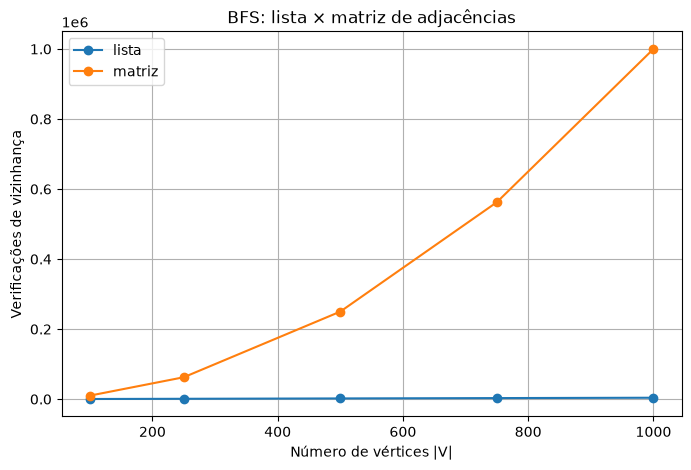

In [36]:
plt.figure(figsize=(8, 5))

for representacao in resumo["representacao"].unique():
    parte = resumo[resumo["representacao"] == representacao]

    plt.plot(
        parte["V"],
        parte["verificacoes_medias"],
        marker="o",
        label=representacao
    )

plt.xlabel("Número de vértices |V|")
plt.ylabel("Verificações de vizinhança")
plt.title("BFS: lista × matriz de adjacências")
plt.legend()
plt.grid()
plt.show()

# Python — gráfico de tempo

O tempo pode apresentar ruído e depende da máquina. Ele deve ser interpretado juntamente com a contagem de operações.

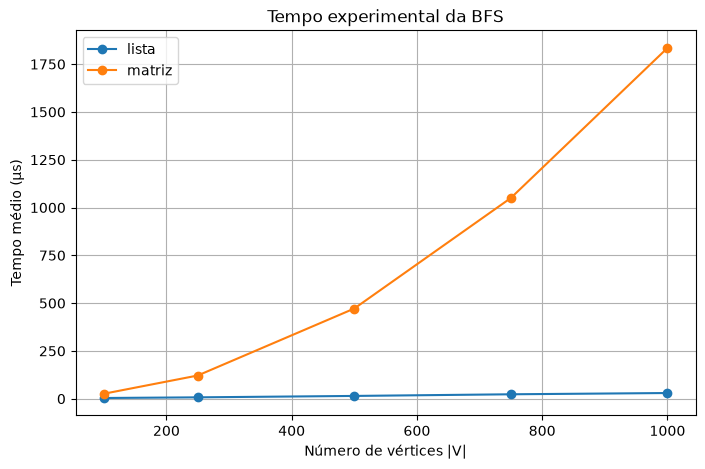

In [37]:
plt.figure(figsize=(8, 5))

for representacao in resumo["representacao"].unique():
    parte = resumo[resumo["representacao"] == representacao]

    plt.plot(
        parte["V"],
        parte["tempo_medio_us"],
        marker="o",
        label=representacao
    )

plt.xlabel("Número de vértices |V|")
plt.ylabel("Tempo médio (µs)")
plt.title("Tempo experimental da BFS")
plt.legend()
plt.grid()
plt.show()

### Análise do experimento

- **Lista:** o número de verificações é exatamente 2|E| = 4|V|. Cada aresta aparece nas duas listas, e o grafo é conexo, então todas as listas são percorridas. O custo é Θ(|V| + |E|).
- **Matriz:** o número de verificações é exatamente |V|², porque cada vértice removido testa a linha inteira. O custo é Θ(|V|²).
- Para |V| = 1000, a lista faz 4.000 verificações e a matriz faz 1.000.000, ou seja, 250 vezes mais.
- O tempo segue o mesmo padrão, com ruído. Ao dobrar |V| de 500 para 1000, o tempo da lista cresce cerca de 2× (linear) e o da matriz cerca de 4× (quadrático).
- A contagem de verificações é determinística e confirma a análise assintótica. O tempo depende da máquina e do cache.

# Exercício 9 — Detecção de ciclo em grafo não dirigido

Durante uma BFS em um grafo **não dirigido**, se ao examinar a aresta `u-v`:

- `v` já foi visitado;
- e `v != pai[u]`;

então encontramos evidência de um ciclo.

Implemente:

```c
int possui_ciclo_bfs(const GrafoLista *g);
```

A função deve funcionar também em grafos desconexos, portanto precisa iniciar uma BFS em cada componente ainda não visitada.

In [35]:
%%writefile ciclo_bfs.c
#include "fila.h"
#include "grafo_lista.h"
#include <stdlib.h>

int possui_ciclo_bfs(const GrafoLista *g)
{
    int *visitado = calloc(g->n, sizeof(int));
    int *pai = malloc(g->n * sizeof(int));
    Fila *f = fila_cria(g->n);
    if (visitado == NULL || pai == NULL || f == NULL)
    {
        free(visitado);
        free(pai);
        fila_libera(f);
        return -1;
    }

    int ciclo = 0;
    for (int s = 0; s < g->n && !ciclo; s++)
    {
        if (visitado[s])
            continue;

        visitado[s] = 1;
        pai[s] = -1;
        fila_enfileira(f, s);

        while (!fila_vazia(f) && !ciclo)
        {
            int u;
            fila_desenfileira(f, &u);

            for (NoAdj *p = g->inicio[u]; p != NULL; p = p->prox)
            {
                int v = p->vertice;
                if (!visitado[v])
                {
                    visitado[v] = 1;
                    pai[v] = u;
                    fila_enfileira(f, v);
                }
                else if (v != pai[u])
                {
                    ciclo = 1;
                    break;
                }
            }
        }
    }

    free(visitado);
    free(pai);
    fila_libera(f);
    return ciclo;
}

Overwriting ciclo_bfs.c


In [36]:
%%writefile teste_ciclo.c
#include <stdio.h>
#include "grafo_lista.h"

int possui_ciclo_bfs(const GrafoLista *g);

int main(void) {
    GrafoLista *arvore = grafo_lista_cria(5);
    grafo_lista_adiciona_aresta(arvore, 0, 1);
    grafo_lista_adiciona_aresta(arvore, 1, 2);
    grafo_lista_adiciona_aresta(arvore, 1, 3);
    grafo_lista_adiciona_aresta(arvore, 3, 4);

    GrafoLista *ciclo = grafo_lista_cria(4);
    grafo_lista_adiciona_aresta(ciclo, 0, 1);
    grafo_lista_adiciona_aresta(ciclo, 1, 2);
    grafo_lista_adiciona_aresta(ciclo, 2, 0);
    grafo_lista_adiciona_aresta(ciclo, 2, 3);

    printf("Árvore possui ciclo? %s\n",
           possui_ciclo_bfs(arvore) ? "sim" : "não");

    printf("Segundo grafo possui ciclo? %s\n",
           possui_ciclo_bfs(ciclo) ? "sim" : "não");

    grafo_lista_libera(arvore);
    grafo_lista_libera(ciclo);

    return 0;
}

Overwriting teste_ciclo.c


In [38]:
!gcc -Wall -Wextra -O2 -std=c11 \
    fila.c grafo_lista.c ciclo_bfs.c teste_ciclo.c \
    -o teste_ciclo

!./teste_ciclo

Árvore possui ciclo? não
Segundo grafo possui ciclo? sim


# Exercício 10 — BFS minimiza arestas, não soma de pesos

Considere:

```text
A --100-- B
 \       /
  1     1
   \   /
     C
```

Há dois caminhos de `A` até `B`:

```text
A -> B       : 1 aresta, custo 100
A -> C -> B  : 2 arestas, custo 2
```

A BFS prefere o primeiro porque minimiza **número de arestas**.

### Responda

1. A BFS está errada ao devolver `A -> B`?
2. Que quantidade ela realmente minimiza?
3. Por que não podemos usar BFS diretamente quando pesos diferentes representam custos?
4. Pesquise posteriormente qual algoritmo é apropriado quando os pesos são não negativos.

> Não implemente outro algoritmo nesta atividade. O objetivo é compreender o limite de aplicação da BFS.

### Respostas

1. Não. A BFS promete o caminho com **menor número de arestas**, e `A -> B` tem 1 aresta. Ela está correta para o que se propõe a fazer.
2. Ela minimiza o número de arestas do caminho (`dist[v]`), não a soma dos pesos.
3. A BFS supõe que toda aresta tem o mesmo custo. Um vértice é fixado na primeira vez em que é descoberto, ou seja, pelo caminho com menos arestas, e nunca é reavaliado. Um caminho com mais arestas e custo menor (`A -> C -> B`, custo 2) é ignorado. A BFS só serve diretamente quando todos os pesos são iguais.
4. Para pesos não negativos, o algoritmo apropriado é o de **Dijkstra**, que usa uma fila de prioridade ordenada pela distância acumulada. Como complemento: com pesos 0/1 existe a BFS 0-1 com deque, e com pesos negativos usa-se Bellman-Ford.

# Questões finais

1. Qual é o papel da fila FIFO na descoberta por camadas?
2. Por que marcar no enfileiramento evita duplicatas?
3. O que `dist[v]` representa?
4. O que `pai[v]` permite fazer?
5. Por que a ordem das listas de adjacência pode mudar a árvore BFS?
6. Essa ordem pode mudar a distância mínima encontrada?
7. O que ocorre se o grafo for desconexo?
8. Por que BFS encontra caminhos mínimos em número de arestas?
9. Compare a quantidade de verificações de vizinhança entre lista e matriz.
10. Quando uma matriz de adjacências ainda pode ser uma escolha interessante?
11. Qual é o espaço adicional da BFS além da própria representação do grafo?
12. Qual a diferença entre:
    - "vértice descoberto";
    - "vértice retirado da fila";
    - "vértice ainda não alcançado"?

### Respostas

1. **Papel da fila FIFO:** os vértices saem na mesma ordem em que foram descobertos. Os vértices da camada k+1 só são descobertos enquanto se processa a camada k, e entram atrás de todos os da camada k. Assim, a fila contém no máximo duas camadas consecutivas, sempre em ordem. Com uma pilha (LIFO), o percurso viraria uma busca em profundidade.
2. **Marcar no enfileiramento:** a partir do momento em que `v` é enfileirado, o teste `!visitado[v]` falha para qualquer outra aresta que chegue em `v`, mesmo com `v` ainda na fila. Assim, cada vértice entra na fila uma única vez.
3. **`dist[v]`:** é o número mínimo de arestas de um caminho da origem até `v`, ou -1 se `v` não é alcançável.
4. **`pai[v]`:** permite reconstruir um caminho mínimo da origem até qualquer vértice: sobe-se por `pai[]` até a origem e inverte-se a sequência. O vetor `pai[]` representa a árvore BFS.
5. **Ordem das listas e a árvore BFS:** o primeiro vizinho que descobre `v` vira o seu pai. Se as listas mudarem de ordem, outro vértice da camada anterior pode chegar primeiro. Por exemplo, `E` pode ter pai `B` ou `C`.
6. **A ordem muda a distância?** Não. `dist[v]` é a distância no grafo, um valor único que não depende da ordem dos vizinhos. Só a árvore (`pai[]`) e a ordem de visita podem mudar.
7. **Grafo desconexo:** a BFS a partir de `s` só alcança a componente de `s`. Os demais vértices ficam com `visitado = 0`, `dist = -1` e `pai = -1`. Para percorrer o grafo todo, inicia-se uma nova BFS em cada vértice ainda não visitado, o que forma uma floresta (como em `componentes_bfs`).
8. **Por que a BFS encontra caminhos mínimos:** os vértices saem da fila em ordem não decrescente de `dist`, e um vértice descoberto a partir de `u` recebe `dist[u] + 1`. Suponha que `v` tivesse um caminho mais curto que `dist[v]`. O vértice `w` anterior a `v` nesse caminho teria distância menor que `dist[u]`, sairia da fila antes de `u` e já teria descoberto `v` com uma distância menor. Isso é uma contradição.
9. **Verificações na lista e na matriz:** na lista são 2|E| (cada aresta vista nos dois sentidos), o que dá Θ(|V| + |E|). Na matriz são |V| por vértice removido, ou |V|² no total. No experimento (|E| = 2|V|), isso dá 4|V| contra |V|²; para |V| = 1000, 4.000 contra 1.000.000.
10. **Quando a matriz ainda é interessante:** em grafos densos (|E| ≈ |V|²), em que a lista também custaria Θ(|V|²) e a matriz tem melhor localidade de memória e nenhum ponteiro. Também quando se precisa testar se uma aresta existe em O(1), em grafos pequenos, ou em algoritmos de natureza matricial (como Floyd-Warshall e fecho transitivo).
11. **Espaço adicional da BFS:** Θ(|V|), formado pelos vetores `visitado`, `dist`, `pai` e `ordem` (n posições cada) e pela fila, que tem no máximo |V| elementos.
12. **Estados de um vértice:**
    - **ainda não alcançado:** `visitado = 0`; nunca entrou na fila (`dist = -1`);
    - **descoberto:** `visitado = 1`, com `dist` e `pai` já definitivos; pode ainda estar na fila, esperando para ter os vizinhos examinados (é a "fronteira");
    - **retirado da fila:** já saiu da fila, teve todos os vizinhos examinados e aparece em `ordem[]`.

# Desafio opcional — graus de separação

Crie em C um pequeno grafo representando pessoas conectadas por amizade.

Use BFS para responder:

- quantos graus de separação existem entre duas pessoas?
- qual sequência de pessoas forma um caminho mínimo?
- quais pessoas estão exatamente a distância 2 de uma determinada origem?

Depois exporte:

```text
pessoa,distancia
```

para CSV e faça **apenas a visualização** das distâncias em Python.

Esse exercício aproxima BFS de aplicações de redes sociais e Sistemas de Informação.

### Solução do desafio

Grafo de amizades com 10 pessoas. A pessoa `Joao` não tem amigos, para mostrar um vértice inalcançável (distância -1). O programa C usa `bfs_lista` e `reconstroi_caminho` e exporta `pessoa,distancia`.

In [38]:
%%writefile graus_separacao.c
#include "bfs.h"
#include "grafo_lista.h"
#include <stdio.h>

#define N 10

int reconstroi_caminho(const int pai[], int origem, int destino, int caminho[],
                       int capacidade);

int main(void)
{
    const char *nomes[N] = {"Ana",   "Bruno", "Carla", "Diego", "Elisa",
                            "Fabio", "Gabi",  "Hugo",  "Iris",  "Joao"};
    int amizades[][2] = {{0, 1}, {0, 2}, {1, 3}, {2, 3}, {2, 4},
                         {3, 5}, {4, 6}, {5, 7}, {6, 7}, {7, 8}};
    int m = sizeof(amizades) / sizeof(amizades[0]);

    GrafoLista *g = grafo_lista_cria(N);
    if (g == NULL)
    {
        fprintf(stderr, "\n\n***\nFalha ao alocar memoria para: g\n***\n");
        return 1;
    }

    for (int i = 0; i < m; i++)
        grafo_lista_adiciona_aresta(g, amizades[i][0], amizades[i][1]);

    int origem = 0, destino = 8;
    int visitado[N], dist[N], pai[N], ordem[N], tam = 0;
    bfs_lista(g, origem, visitado, dist, pai, ordem, &tam);

    printf("Graus de separacao entre %s e %s: %d\n", nomes[origem],
           nomes[destino], dist[destino]);

    int caminho[N];
    int k = reconstroi_caminho(pai, origem, destino, caminho, N);
    printf("Caminho minimo: ");
    for (int i = 0; i < k; i++)
    {
        if (i)
            printf(" -> ");
        printf("%s", nomes[caminho[i]]);
    }
    printf("\n");

    printf("Pessoas a distancia 2 de %s:", nomes[origem]);
    for (int v = 0; v < N; v++)
    {
        if (dist[v] == 2)
            printf(" %s", nomes[v]);
    }
    printf("\n");

    FILE *arq = fopen("graus_separacao.csv", "w");
    if (arq == NULL)
    {
        grafo_lista_libera(g);
        return 1;
    }

    fprintf(arq, "pessoa,distancia\n");
    for (int v = 0; v < N; v++)
        fprintf(arq, "%s,%d\n", nomes[v], dist[v]);

    fclose(arq);
    grafo_lista_libera(g);

    printf("Arquivo graus_separacao.csv criado.\n");
    return 0;
}

Overwriting graus_separacao.c


In [39]:
!gcc -Wall -Wextra -O2 -std=c11 \
    fila.c grafo_lista.c bfs.c caminho.c graus_separacao.c \
    -o graus_separacao

!./graus_separacao

Graus de separacao entre Ana e Iris: 5
Caminho minimo: Ana -> Bruno -> Diego -> Fabio -> Hugo -> Iris
Pessoas a distancia 2 de Ana: Diego Elisa
Arquivo graus_separacao.csv criado.


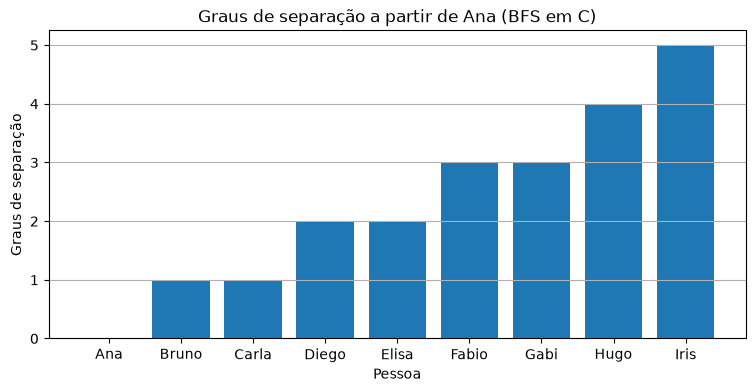

Inalcançáveis: Joao


In [40]:
graus = pd.read_csv("graus_separacao.csv")

alcancaveis = graus[graus["distancia"] >= 0].sort_values("distancia")

plt.figure(figsize=(9, 4))
plt.bar(alcancaveis["pessoa"], alcancaveis["distancia"])
plt.xlabel("Pessoa")
plt.ylabel("Graus de separação")
plt.title("Graus de separação a partir de Ana (BFS em C)")
plt.grid(axis="y")
plt.show()

print("Inalcançáveis:", ", ".join(graus[graus["distancia"] < 0]["pessoa"]))